## Chordsense : DSP Analysis

This jupyter notebook is designed to study and analyze DSP analysis in Python.
Python is quite useful for its various libraries, we will use these libraries. It is also useful for plotting.

In [1]:
import importlib
import numpy as np
import matplotlib.pyplot as plt
from dsp.sine import sine as sine
import dsp.fourier_transform as ft
import dsp.fft as fft

importlib.reload(ft)
dft = ft.dft
amplitude_spectrum = ft.amplitude_spectrum

We will now just generate a sine wave.

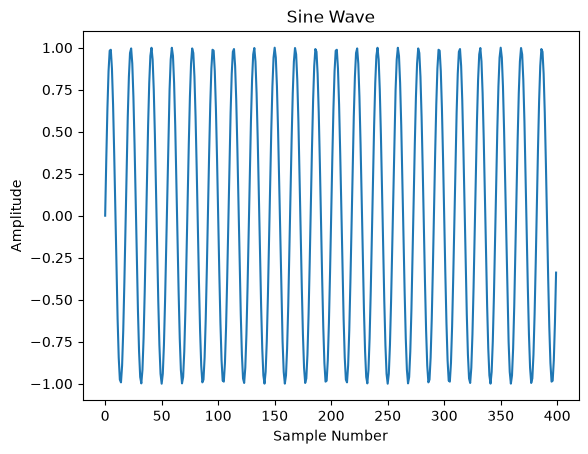

In [5]:
# Use matplotlib's interactive mode to generate a sine wave

sine_wave = sine(440, 0.05, 8000)  # Generate a sine wave with frequency 1 Hz, sample rate 0.01 s, and 1000 samples

plt.ion()  # Turn on interactive mode
plt.plot(sine_wave)  # Plot the sine wave
plt.title("Sine Wave")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.show()  # Display the plot

Now let's try the C chord.

C3 = 130.81 Hz
E3 = 164.81 Hz
G3 = 196.00 Hz

Let's sample this at 44100 Hz, take 44100 samples, so 1 second of recording.

First let's plot the C chord. We will use the numpy's sine function instead.

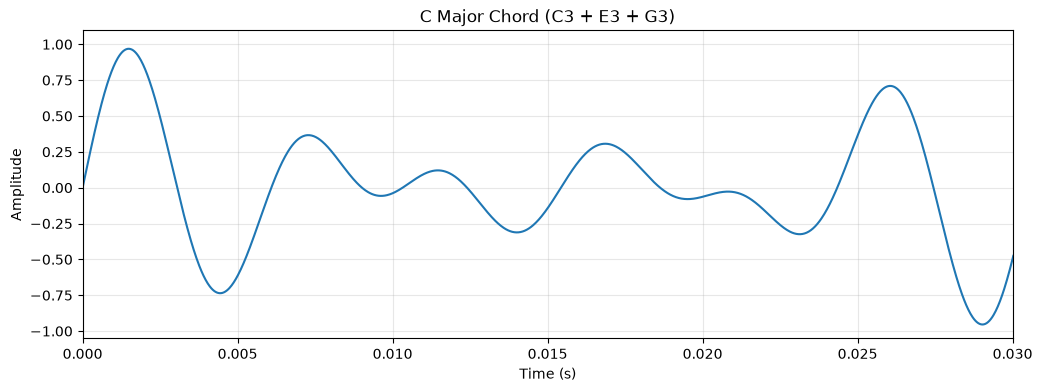

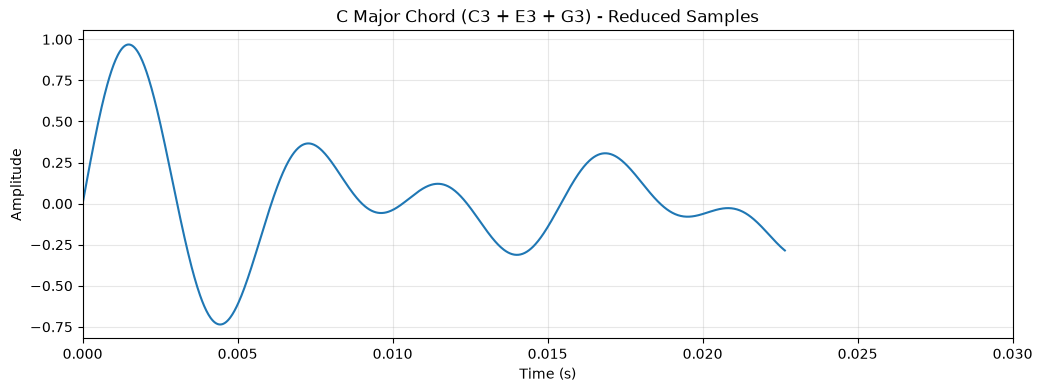

In [6]:
# C major chord: C3, E3, G3
fs = 44100
n_samples = 44100
n_reduced_samples = 1000  # Reduce to first 1000 samples for plotting

# Generate time vector, samples from 0 to 1 second
# Each time step is 1/fs, so t = [0, 1/fs, 2/fs, ..., (n_samples-1)/fs]
t = np.arange(n_samples) / fs
t_reduced = np.arange(n_reduced_samples) / fs  # Reduced time vector for plotting

# The 44100 sample case #

# Our notes: C3 (130.81 Hz), E3 (164.81 Hz), G3 (196.00 Hz)
c3 = np.sin(2 * np.pi * 130.81 * t)
e3 = np.sin(2 * np.pi * 164.81 * t)
g3 = np.sin(2 * np.pi * 196.00 * t)

# We normalize to avoid clipping when we sum the waves.
c_chord = (c3 + e3 + g3) / 3

# The reduced sample case for plotting

c_3_reduced = np.sin(2 * np.pi * 130.81 * t_reduced)
e_3_reduced = np.sin(2 * np.pi * 164.81 * t_reduced)
g_3_reduced = np.sin(2 * np.pi * 196.00 * t_reduced)
c_chord_reduced = (c_3_reduced + e_3_reduced + g_3_reduced) / 3

# Plot the C major chord waveform
plt.figure(figsize=(12, 4))
plt.plot(t, c_chord)
plt.title("C Major Chord (C3 + E3 + G3)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.03)  # zoom in to see waveform shape
plt.grid(True, alpha=0.3)
plt.show()

# Plot the reduced C major chord waveform
plt.figure(figsize=(12, 4))
plt.plot(t_reduced, c_chord_reduced)
plt.title("C Major Chord (C3 + E3 + G3) - Reduced Samples")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.xlim(0, 0.03)  # zoom in to see waveform shape
plt.grid(True, alpha=0.3)
plt.show()

Next, let's proceed to create a frequency spectrum by performing the DFT. The code below works, but it will take a very long time to actually load the results with 44100 samples

The complexity time is O(n^2), that complexity time becomes very long when faced with 44100 samples.

Therefore we will only use 1000 samples for this example.

mean(c_chord_reduced) = 0.03903399948926757
N = 1000 delta_f = 44.1 Hz
target 130.81 Hz -> nearest bin 132.30 Hz, amplitude 0.310582
target 164.81 Hz -> nearest bin 176.40 Hz, amplitude 0.261145
target 196.00 Hz -> nearest bin 176.40 Hz, amplitude 0.261145


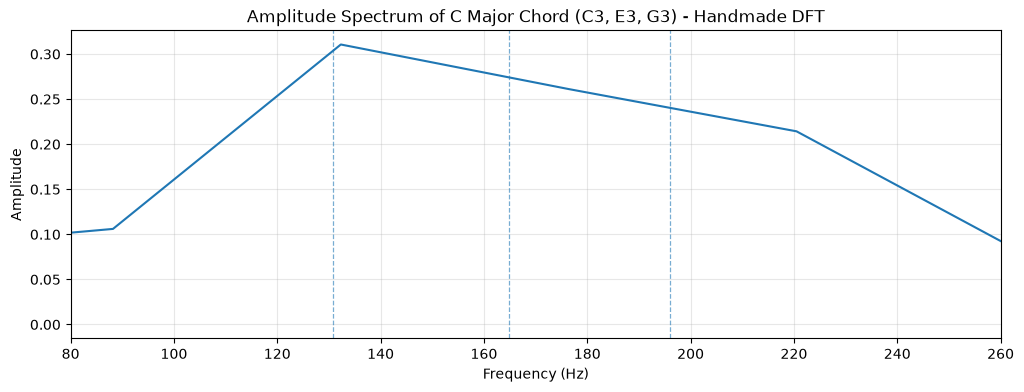

In [7]:
# there is probably a DC bias
print("mean(c_chord_reduced) =", np.mean(c_chord_reduced))

# Remove DC bias from the short window, then compute spectrum with handmade DFT
signal = c_chord_reduced - np.mean(c_chord_reduced)
complex_spectrum = dft(signal)
amps = amplitude_spectrum(complex_spectrum)

# Manual frequency axis for single-sided spectrum: f_k = k * fs / N
N = len(signal)
freqs = np.arange(N // 2 + 1) * fs / N

# Inspect where the three note frequencies land
targets = [130.81, 164.81, 196.00]

print('N =', N, 'delta_f =', fs / N, 'Hz')
for target in targets:
    idx = np.argmin(np.abs(freqs - target))
    print(f'target {target:.2f} Hz -> nearest bin {freqs[idx]:.2f} Hz, amplitude {amps[idx]:.6f}')

# Plot in Hz and zoom to the musical region
plt.figure(figsize=(12, 4))
plt.plot(freqs, amps)
for f in targets:
    plt.axvline(f, linestyle='--', linewidth=0.9, alpha=0.6)
plt.title('Amplitude Spectrum of C Major Chord (C3, E3, G3) - Handmade DFT')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim(80, 260)
plt.grid(True, alpha=0.3)
plt.show()

To get the frequency spectrum of the C chord with 44100 samples, it is best to use the Fast Fourier Transform algorithm.

It works recursively, essentially diviving every odd and even element in the sample set, until it reaches the base case. We will use Python's np. equivalent.

original N = 44100 padded N = 65536 delta_f = 0.67291259765625 Hz
target 130.81 Hz -> nearest bin 130.55 Hz, amplitude 0.300280
target 164.81 Hz -> nearest bin 164.86 Hz, amplitude 0.333760
target 196.00 Hz -> nearest bin 195.82 Hz, amplitude 0.316092


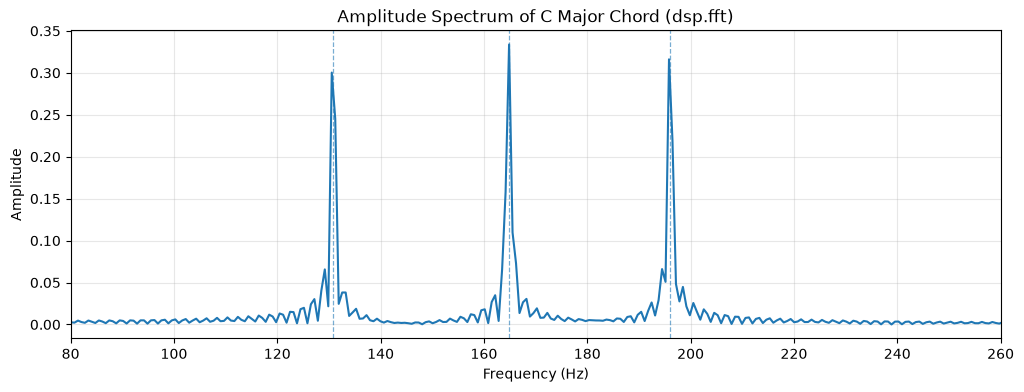

In [8]:
# Use FFT implementation from dsp.fft on the full C chord
signal_dsp = c_chord - np.mean(c_chord)  # remove DC bias
N_dsp = len(signal_dsp)

# dsp.fft needs power-of-two length, so pad with zeros
N_fft = 1 << (N_dsp - 1).bit_length()
signal_fft = np.zeros(N_fft)
signal_fft[:N_dsp] = signal_dsp

fft_complex_dsp = fft.fft(signal_fft)

# Scale by original (unpadded) sample count so amplitudes stay comparable
amps_dsp = (2.0 / N_dsp) * np.abs(fft_complex_dsp[: N_fft // 2 + 1])
amps_dsp[0] *= 0.5
freqs_dsp = np.arange(N_fft // 2 + 1) * fs / N_fft

print('original N =', N_dsp, 'padded N =', N_fft, 'delta_f =', fs / N_fft, 'Hz')
for f0 in targets:
    idx = np.argmin(np.abs(freqs_dsp - f0))
    print(f'target {f0:.2f} Hz -> nearest bin {freqs_dsp[idx]:.2f} Hz, amplitude {amps_dsp[idx]:.6f}')

# Plot the amplitude spectrum from dsp.fft
plt.figure(figsize=(12, 4))
plt.plot(freqs_dsp, amps_dsp)
for f0 in targets:
    plt.axvline(f0, linestyle='--', linewidth=0.9, alpha=0.6)
plt.title('Amplitude Spectrum of C Major Chord (dsp.fft)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Amplitude')
plt.xlim(80, 260)
plt.grid(True, alpha=0.3)
plt.show()

In any case, this was just to explore the capabilities of FFT. 

From now on, we will use the numpy's fft version.

## Pipeline


In this section we take a look at the pipeline.

Before accessing the pipeline, it is important to first know about the use of harmonics. This is because they are very common in musical instruments, thus should be accounted for.

A harmonic is a frequency component of a complex periodic wave that is an exact integer multiple of the fundamental frequency. They shape the timbre as well, in other words, they are the reason why the sound of a guitar sounds like a guitar. 

Generally in DSP, you need to account for harmonics since they can cause aliasing. Harmonics can exceed the Nyquist frequency, thus it folds back around the frequency spectrum. Harmonics also add extra peaks, which the pipeline may read as extra notes.

Therefore, if you wanted to test the C major chord, you would expect 3 peaks, but actually get more than 3 due to harmonics



### Harmonic Example

As an example to figuring out harmonics, let's use the **C4** note, which is at **261.63 Hz**.

The **first** harmonic is 1x, thus the frequency remains at 261.63 Hz. This also referred to as the fundamental frequency.

The **second** harmonic is 2x, so it is the double of the fundamental frequency. It is at 523.25 Hz. The closest note to that frequency is C5. 

To convert any frequency ($f$ in Hz) to a musical note, we use the standard MIDI note formula:

$$\text{MIDI Note} = 69 + 12 \times \log_2\left(\frac{f}{440}\right)$$

#### Harmonic Interval Reference Table

| Harmonic | Multiplier ($r$) | Semitones Above Root ($12 \times \log_2 r$) | Musical Interval (from Root) |
| :--- | :--- | :--- | :--- |
| **1st** | $1$ | $0$ | Unison (Root Note) |
| **2nd** | $2$ | $+12$ | Octave |
| **3rd** | $3$ | $\approx +19.02$ | Octave + Perfect 5th |
| **4th** | $4$ | $+24$ | Two Octaves |
| **5th** | $5$ | $\approx +27.86$ | Two Octaves + Major 3rd |

Therefore, to complete the C major chord;

| Harmonic ($n$) | C Series (Root) | E Series (Third) | G Series (Fifth) | Notable Overlaps / Additions |
| :--- | :--- | :--- | :--- | :--- |
| **1st ($1f_0$)** | C4 | E4 | G4 | Fundamental Chord (C, E, G) |
| **2nd ($2f_0$)** | C5 | E5 | G5 | Octaves up |
| **3rd ($3f_0$)** | G5 | B5 | D6 | Fifths & Ninths |
| **4th ($4f_0$)** | C6 | E6 | G6 | Double Octaves |
| **5th ($5f_0$)** | E6 | **G#6** | B6 | **G#6 appears** (from E's 5th harmonic) |

The `harmonic_note` function takes any frequency, considers it as the fundamental frequencies, then creates it's harmonics. As a default, it returns an array-like of 5 harmonics. It also has the important capability of **damping**. 

**Damping** is very important in digital signal processing as it makes the less relevant harmonics have a smaller amplitude. Otherwise, all amplitudes, regardless of harmonic importance, are the same.

**Decay Rate** is also important because it governs how quickly different harmonics fade out over time—with higher frequencies dying out faster than the fundamental. This gives synthesized sounds a natural, acoustic evolution rather than a static, robotic tone.

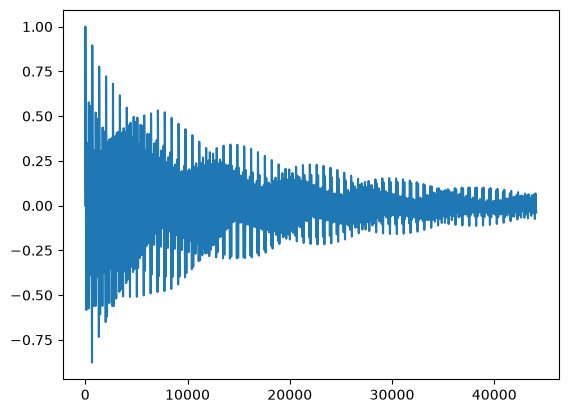

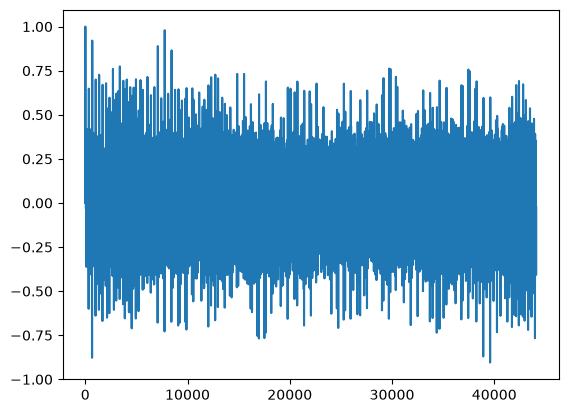

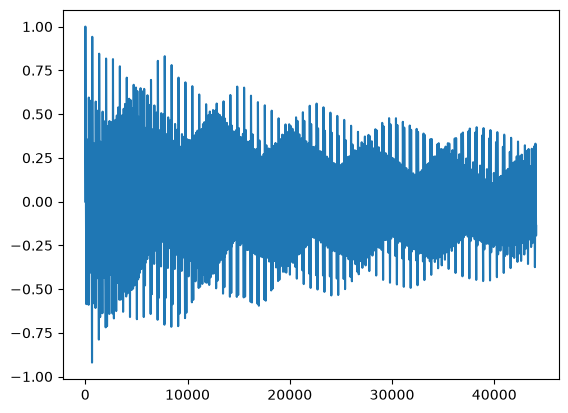

In [ ]:
# Import the pipeline
from dsp.sine import harmonic_note

# Generate a DAMPED harmonic note, the C4 chord.
notes_damped_C = harmonic_note(261.63, 1, damped=True)
notes_damped_E = harmonic_note(329.63, 1, damped=True)
notes_damped_G = harmonic_note(392.00, 1, damped=True)

# Generate the undamped chord (same amplitudes for the C4 chord's harmonics)
notes_C = harmonic_note(261.63, 1)
notes_E = harmonic_note(329.63, 1)
notes_G = harmonic_note(392.00, 1)

# Next let's generate the damped c chord but with a shorter decay rate
notes_damped_short_C = harmonic_note(261.63, 1, damped=True, decay_rate=0.5)
notes_damped_short_E = harmonic_note(329.63, 1, damped=True, decay_rate=0.5)
notes_damped_short_G = harmonic_note(392.00, 1, damped=True, decay_rate=0.5)

# Normalize the chord
damped_chord = notes_damped_C + notes_damped_E + notes_damped_G
chord = notes_C + notes_E + notes_G
damped_short_chord = notes_damped_short_C + notes_damped_short_E + notes_damped_short_G

# Normalize the chords
damped_normalized_chord = damped_chord / max(abs(damped_chord))
chord = chord / max(abs(chord))
damped_short_chord = damped_short_chord / max(abs(damped_short_chord))

# Show the damped chord
plt.plot(damped_normalized_chord)
plt.show()

# Show the undamped chord
plt.plot(chord)
plt.show()

# Show the short damped chord
plt.plot(damped_short_chord)
plt.show()

Now, let's run the exact-matching pipeline with damped and undamped chords.

This experiment shows that stronger harmonics can add pitch classes and break an exact chord lookup. Damping helps some synthesized examples, but real instrument recordings also contain harmonics. The detector therefore needs a way to distinguish strong evidence for played notes from weaker harmonic contributions. The next section keeps amplitude information with chroma.


In [ ]:
from pipeline.chord_guess import prepare_frame, signal_to_peaks, guess_chord
from dsp.note_tools import frequency_to_note

def detect_chord(signal):

    # Prepare the frame for analysis
    frame, weights = prepare_frame(signal, sample_rate=44100, frame_size=44100)

    # Find the peaks and the notable frequencies
    peaks = signal_to_peaks(frame, 44100, window_weights=weights)

    # Print each peak's info
    for p in sorted(peaks, key=lambda p: p["frequency_hz"]):

        # Convert to note info
        info = frequency_to_note(p["frequency_hz"])
        print(
            f"{p['frequency_hz']:.2f} Hz",
            info["note"],
            f"{info['cents']:+.2f} cents",
            f"amplitude={p['amplitude']:.4f}",
        )

    # Number of peaks
    print("Peak count:", len(peaks))
    # Guess the chord
    print("Chord:", guess_chord(peaks))

# Example usage

print("Detecting the DAMPED C chord")
detect_chord(damped_normalized_chord)
print("\nDetecting the C chord")
detect_chord(chord)
print("\nDetecting the short damped C chord")
detect_chord(damped_short_chord)

Detecting the DAMPED C chord
262.00 Hz C4 +2.48 cents amplitude=0.0779
330.00 Hz E4 +1.96 cents amplitude=0.0779
392.00 Hz G4 +0.02 cents amplitude=0.0850
523.00 Hz C5 -0.83 cents amplitude=0.0182
659.00 Hz E5 -0.67 cents amplitude=0.0182
784.00 Hz G5 +0.02 cents amplitude=0.0187
Peak count: 6
Chord: C

Detecting the C chord
262.00 Hz C4 +2.48 cents amplitude=0.0792
330.00 Hz E4 +1.96 cents amplitude=0.0792
392.00 Hz G4 +0.02 cents amplitude=0.0866
523.00 Hz C5 -0.83 cents amplitude=0.0829
659.00 Hz E5 -0.67 cents amplitude=0.0829
785.00 Hz G5 +2.23 cents amplitude=0.0475
989.00 Hz B5 +2.16 cents amplitude=0.0860
1047.00 Hz C6 +0.82 cents amplitude=0.0745
1176.00 Hz D6 +1.98 cents amplitude=0.0866
1308.00 Hz E6 -13.86 cents amplitude=0.0854
1319.00 Hz E6 +0.64 cents amplitude=0.0745
1568.00 Hz G6 +0.02 cents amplitude=0.0866
1648.00 Hz G#6 -13.83 cents amplitude=0.0854
1960.00 Hz B6 -13.67 cents amplitude=0.0866
Peak count: 14
Chord: None

Detecting the short damped C chord
262.00 Hz C

### Chroma: weighting by amplitude

The results above show the problem. `guess_chord` turns every peak into a note, and every note counts equally. A loud fundamental and a faint harmonic carry the same weight, so the harmonics add foreign notes:

| Harmonic | Interval above the fundamental | Pitch class after `% 12` |
|---|---|---|
| 2, 4 | 1, 2 octaves | same as the root, harmless |
| 3 | octave + fifth | the fifth, a **new** pitch class |
| 5 | 2 octaves + major third | the major third (-14 cents), a **new** pitch class |

For C major, E's harmonics add **B** and **G#**, and G's harmonics add **D**. The pitch-class set stops matching any chord.

A **chroma vector** fixes this by keeping the amplitude. Each peak's amplitude is **added** into one of 12 bins (C, C#, ..., B):

- Octave harmonics land in their own note's bin and make it **stronger**.
- Non-octave harmonics only add a little to a foreign bin.

At this stage, keep only bins that are at least 60% of the strongest (`filter_chroma`) and pass those pitch classes to `chord_extract`. The notebook helper `guess_chord_threshold` preserves this original approach, so this section demonstrates chroma with a threshold before introducing template matching.

`build_chroma` and `filter_chroma` live in `dsp/chroma_tools.py`. `guess_chord` remains the exact matcher. Template scoring and the current pipeline wrapper are introduced in a later section.

In [ ]:
from dsp.chroma_tools import build_chroma, filter_chroma
from dsp.note_tools import NOTE_NAMES_SHARP
from dsp.chord_tools import chord_extract

def guess_chord_threshold(peaks, threshold=0.6):
    # Preserve the original yes/no chroma approach for this notebook stage.
    chroma = build_chroma(peaks)
    pitch_classes = filter_chroma(chroma, threshold=threshold)
    return chord_extract(pitch_classes)


def compare_chord(signal):
    # This function compares the chord content of a signal using chroma vectors
    # Same preparation and peaks as detect_chord

    # Prepare the frame and find spectral peaks
    frame, weights = prepare_frame(signal, sample_rate=44100, frame_size=44100)
    peaks = signal_to_peaks(frame, 44100, window_weights=weights)

    # Build the chroma vector and normalize it to the strongest bin
    chroma = build_chroma(peaks)

    # Compute the relative chroma by dividing by the strongest bin
    relative = chroma / chroma.max() if chroma.max() > 0 else chroma.copy()

    # Print every non-empty bin
    for pc in range(12):

        # Only print non-empty bins
        if chroma[pc] > 0:
            print(f"{NOTE_NAMES_SHARP[pc]:<3} sum={chroma[pc]:.4f}  relative={relative[pc]:.2f}")

    # Filter the chroma vector to keep only the significant pitch classes
    kept = [NOTE_NAMES_SHARP[pc] for pc in filter_chroma(chroma, threshold=0.6)]

    # Print the kept pitch classes for reference
    print("Baseline kept pitch classes:", ", ".join(kept))
    print("Threshold chroma:  ", guess_chord_threshold(peaks))
    print("guess_chord:       ", guess_chord(peaks))

    return relative

# Compare the chord content of different signals using chroma vectors
chords = {
    "Damped C chord": damped_normalized_chord,
    "Undamped C chord": chord,
    "Short damped C chord": damped_short_chord,
}

# Dictionary to store the relative chroma vectors for each signal
relative_chromas = {}

# Iterate over each signal and compute its relative chroma vector
for name, signal in chords.items():
    # Print the name of the signal being analyzed
    print(name)
    relative_chromas[name] = compare_chord(signal)
    print()

Damped C chord
C   sum=0.0961  relative=0.93
E   sum=0.0961  relative=0.93
G   sum=0.1036  relative=1.00
Baseline kept pitch classes: C, E, G
Threshold chroma:   C
guess_chord:        C

Undamped C chord
C   sum=0.2367  relative=0.73
D   sum=0.0866  relative=0.27
E   sum=0.3220  relative=1.00
G   sum=0.2208  relative=0.69
G#  sum=0.0854  relative=0.27
B   sum=0.1726  relative=0.54
Baseline kept pitch classes: C, E, G
Threshold chroma:   C
guess_chord:        None

Short damped C chord
C   sum=0.2367  relative=0.98
D   sum=0.0353  relative=0.15
E   sum=0.2367  relative=0.98
G   sum=0.2420  relative=1.00
B   sum=0.0350  relative=0.14
Baseline kept pitch classes: C, E, G
Threshold chroma:   C
guess_chord:        None



The chroma vectors make the difference easy to see. The dashed line is the 60% threshold, and only the bars above it are kept.

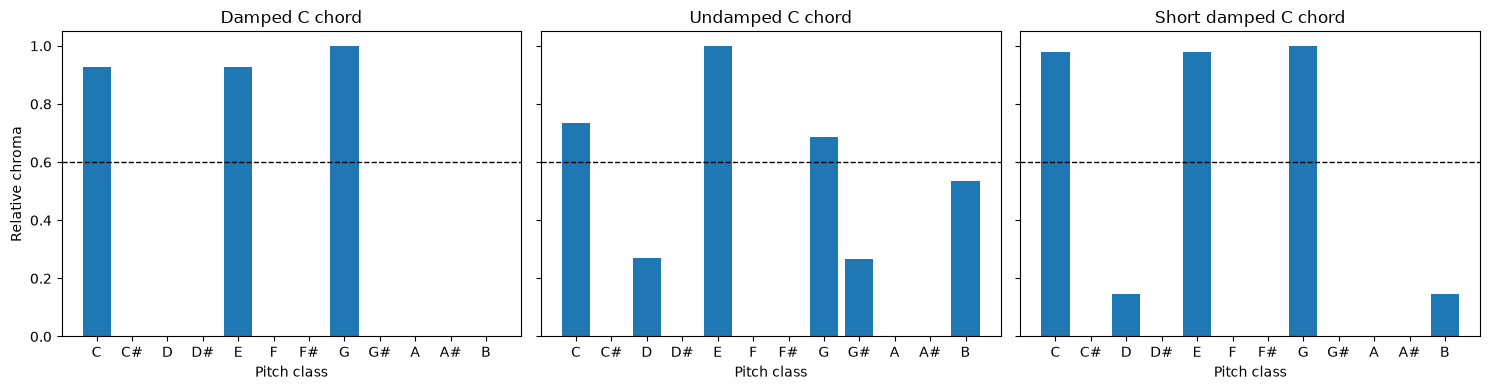

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (name, relative) in zip(axes, relative_chromas.items()):
    ax.bar(NOTE_NAMES_SHARP, relative)
    ax.axhline(0.6, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Pitch class")

axes[0].set_ylabel("Relative chroma")
plt.tight_layout()
plt.show()

### Limits of the threshold

The undamped chord is the hardest case. Its harmonics are as loud as the fundamentals, so B reaches about 54% and only just falls below the 60% threshold. Instruments with strong upper harmonics could push it over.

Summing also has a side effect: notes **doubled across octaves** get stronger bins too. A note that is played only once can fall below the threshold, even when it is a real chord tone.

For example, an Esus4 voicing E2, B2, E3, A3, B3, E4 has three Es, two Bs and one A. In plain sine waves there are no harmonics at all, yet chroma drops the A:

In [57]:
# Esus4 voiced across octaves, using pure sines (no harmonics)
esus4_frequencies = [440 * 2 ** ((n - 69) / 12) for n in (40, 47, 52, 57, 59, 64)]
esus4 = sum(sine(f, 1) for f in esus4_frequencies) / len(esus4_frequencies)

relative_esus4 = compare_chord(esus4)

E   sum=0.4649  relative=1.00
A   sum=0.1667  relative=0.36
B   sum=0.3105  relative=0.67
Baseline kept pitch classes: E, B
Threshold chroma:   E5
guess_chord:        Esus4


`guess_chord` gets this voicing right. The threshold-based `guess_chord_threshold` returns E5 because the single A reaches only about 36% of the E bin.

A fixed cutoff is a trade-off: it can remove harmonics, but it can also remove a real chord tone. This motivates the next step: compare the complete weighted chroma against chord templates, so every bin contributes gradually rather than passing or failing a note threshold.


### Template matching with cosine similarity

Keep all 12 chroma weights. A binary template puts 1 in each chord-tone bin and 0 elsewhere. Cosine similarity compares the shape of that template with the measured weights, independently of overall volume.

1. `cosine_similarity(a, b)` computes one score; a zero vector gives 0.
2. `build_templates()` generates every root and chord shape from the existing vocabulary: 108 templates today.
3. `match_chord(chroma)` checks every template and returns `(best_name, best_score)`. Silence returns `(None, 0.0)`.
4. `guess_chord_chroma(peaks, min_score=0.8)` builds chroma, takes the best match, and optionally rejects a low final score. It no longer calls `filter_chroma` or `chord_extract`.

A final-score cutoff is a heuristic, not a calibrated confidence level. The old 60% note filter above is retained only as an experimental baseline.

The first example uses C=1, E=1, G=0.5. The 60% threshold drops G and leaves C and E, which have no exact match in the vocabulary. Cosine matching keeps the quieter G and returns C with a score near 0.9623. This demonstrates an improvement without claiming that templates solve every harmonic or voicing problem.


In [77]:
from dsp.template_tools import cosine_similarity, build_templates, match_chord

import importlib
import pipeline.chord_guess as chord_pipeline
importlib.reload(chord_pipeline)
from pipeline.chord_guess import guess_chord_chroma
from dsp.chord_tools import chord_extract
from dsp.chroma_tools import filter_chroma

# Build templates and example chroma vector
templates = build_templates()

# Create a chroma vector for C major (12 bins)
example = np.zeros(12)

# Set C major chord in chroma
example[[0, 4, 7]] = [1.0, 1.0, 0.5]  # C, E, and a quieter G

# Print info about the example
print("Template count:", len(templates))
print("C template:", templates["C"])

print("Cosine with C:", cosine_similarity(example, templates["C"]))
print("Threshold chroma:", chord_extract(filter_chroma(example, threshold=0.6)))
print("Best template match:", match_chord(example))
print("Silence:", match_chord(np.zeros(12)))


Template count: 108
C template: [1. 0. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.]
Cosine with C: 0.9622504486493763
Threshold chroma: None
Best template match: ('C', 0.9622504486493763)
Silence: (None, 0.0)


### Compare the best scores

Run the same signals through all three paths: exact lookup, threshold chroma, and scored templates. Print the three highest scores to see when more than one chord fits well. No pitch-class bin is removed during template scoring.


In [ ]:

# Explore chord matching with different methods, append the Esus4 voicing as well
for label, signal in {**chords, "Esus4 voicing": esus4}.items():

    # Prepare the frame and weights
    frame, weights = prepare_frame(signal, sample_rate=44100, frame_size=44100)

    # Find the peaks, at this point, they are still just frequencies
    peaks = signal_to_peaks(frame, 44100, window_weights=weights)

    # Build a chroma vector
    chroma = build_chroma(peaks)

    # Now match the chord, there are no thresholds here
    name, score = match_chord(chroma)

    # Rank all templates by similarity
    ranked = sorted(
        ((name, cosine_similarity(chroma, template)) for name, template in templates.items()),
        key=lambda candidate: candidate[1],
        reverse=True,
    )

    # Print results for this chord
    print(label)
    # raw guess, there is no threshold and all frequency amplitudes are the same.
    print("  Exact matcher:", guess_chord(peaks))

    # Thresholded guess, a threshold of 0.6 is used. It is better but it is still a hard decision
    print("  Threshold chroma:", guess_chord_threshold(peaks))

    # Best template info, using cosine similarity
    print("  Best template:", name, f"score={score:.4f}")
    print("  Accepted at min_score=0.8:", guess_chord_chroma(peaks))
    print("  Top three:", [(name, round(score, 4)) for name, score in ranked[:3]])
    
    # Separator for readability
    print()


Damped C chord
  Exact matcher: C
  Threshold chroma: C
  Best template: C score=0.9994
  Accepted at min_score=0.8: C
  Top three: [('C', 0.9994), ('Cmaj7', 0.8655), ('C7', 0.8655)]

Undamped C chord
  Exact matcher: None
  Threshold chroma: C
  Best template: Cmaj7 score=0.9463
  Accepted at min_score=0.8: Cmaj7
  Top three: [('Cmaj7', 0.9463), ('C', 0.8946), ('Em', 0.8211)]

Short damped C chord
  Exact matcher: None
  Threshold chroma: C
  Best template: C score=0.9928
  Accepted at min_score=0.8: C
  Top three: [('C', 0.9928), ('Cmaj7', 0.9018), ('C7', 0.8598)]

Esus4 voicing
  Exact matcher: Esus4
  Threshold chroma: E5
  Best template: E5 score=0.9399
  Accepted at min_score=0.8: E5
  Top three: [('E5', 0.9399), ('Esus4', 0.9324), ('E', 0.7674)]



The damped C-major examples prefer C. With equally strong upper harmonics, Cmaj7 can score higher than C because the B harmonic is also strong. The uneven Esus4 voicing can still prefer E5 because the two dominant bins align closely with that template.

These are useful failure cases to keep visible. Replacing a hard note cutoff with scoring makes the comparison gradual; it does not by itself separate harmonics from played notes or account for every voicing. A minimum score alone cannot reject a wrong match that already has a high score.


## Tracking Chords Over Time with a Sliding Window

So far we've identified the chord in a single chunk of audio. Real music changes chords
as it plays, so we need to analyze a whole recording and see *when* each chord occurs.

To do this, we use a **sliding window** (also called a framing approach):

1. Take a short slice of audio, called a **frame**.
2. Identify the chord in that frame.
3. Move the window forward by a small step, called the **hop**.
4. Repeat until we reach the end of the signal.

### The two parameters

| Parameter | Meaning | Trade-off |
|-----------|---------|-----------|
| `frame_seconds` | How much audio is analyzed at once | Longer frames give better frequency resolution (clearer notes) but blur chord changes in time |
| `hop_seconds` | How far the window moves each step | Shorter hops track changes more precisely but require more computation |

### Example

With a 1.0 s frame and a 0.1 s hop:

```
step 1:  analyze 0.0 - 1.0 s
step 2:  analyze 0.1 - 1.1 s
step 3:  analyze 0.2 - 1.2 s
...
last:    analyze 9.0 - 10.0 s
```

Consecutive frames overlap heavily, so the chord estimate changes smoothly rather than
jumping in large blocks. A useful analogy is taking snapshots of a moving scene at
regular intervals.

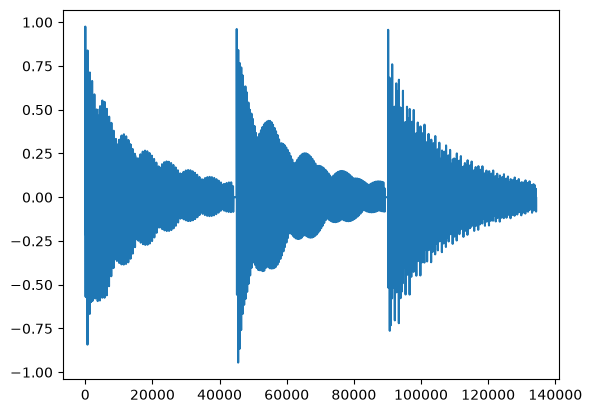

[{'chord': 'C', 'start': 0.2, 'end': 0.9}, {'chord': 'G', 'start': 0.8999999999999999, 'end': 2.0}, {'chord': 'Am', 'start': 1.9999999999999998, 'end': 2.8}]


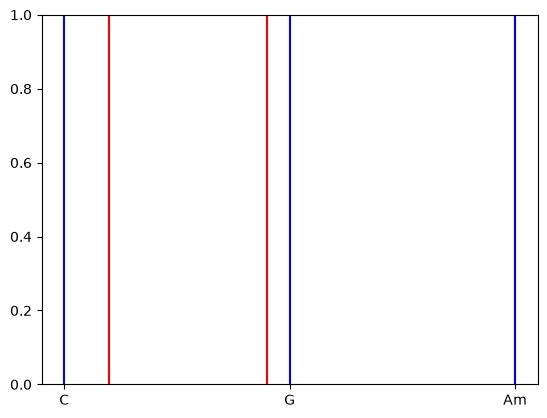

In [8]:
import pipeline.sliding_frame as sliding_frame
import pipeline.chord_guess as chord_guess
import dsp.sine as sine
import matplotlib.pyplot as plt

import numpy as np

# Generate 3 harmonic notes and stick them to the same signal

# We begin by crafting the C major chord
notes_C = sine.harmonic_note(261, 1, damped=True)
notes_E = sine.harmonic_note(330, 1, damped=True)
notes_G = sine.harmonic_note(392, 1, damped=True)

# Next the G chord
notes_G = sine.harmonic_note(392, 1, damped=True)
notes_B = sine.harmonic_note(494, 1, damped=True)
notes_D = sine.harmonic_note(294, 1, damped=True)

# Next the A minor chord
notes_A = sine.harmonic_note(440, 1, damped=True)
# both C and E are added

# To create this signal, add the C major chord together, wait a bit, then add G and Am
notes_C_chord = (notes_C + notes_E + notes_G) / 3
notes_G_chord = (notes_G + notes_B + notes_D) / 3
notes_Am_chord = (notes_A + notes_C + notes_E) /3

# Chords cannot be combined into one at once, there needs to be gaps between them
signal = np.concatenate([notes_C_chord, [0]*1000, notes_G_chord, [0]*1000, notes_Am_chord])

# plot the signal
plt.plot(signal)
plt.show()

result = sliding_frame.chords_over_time(signal, 44100, frame_seconds=0.5, hop_seconds=0.1)
smoothed = sliding_frame.smooth_results(result)
segments = sliding_frame.to_segments(smoothed, 0.1)

# print the segments
print(segments)

# Next, plot the segments
for s in segments:
    plt.axvline(s["start"], color="r")
    plt.axvline(s["chord"], color="b")
plt.show()